# Fatiga: no linealidades tensión–vida

Notebook de apoyo para entender por qué la relación entre el nivel de tensión y la vida a fatiga **no es lineal**.

Estructura:

0. Curva S-N y ecuación de Basquin (referencia base)
1. No linealidades
   1. No linealidad en una entalla (regla de Neuber + Ramberg-Osgood)
   2. Ley de Paris (propagación de grieta)
2. Zonas del comportamiento a fatiga
   1. Fatiga de bajo número de ciclos (LCF) — Coffin-Manson
   2. Fatiga de alto número de ciclos (HCF) — Basquin
   3. Límite de fatiga (endurance limit)

Material de referencia: **acero**, con valores representativos de un acero estructural de alta resistencia (**ilustrativos** — para diseño real usa siempre datos de ensayo certificados del material y proceso concretos).

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# --- Propiedades representativas de un acero estructural de alta resistencia ---
# (valores ilustrativos típicos de literatura de fatiga; NO usar para diseño real
#  sin datos de ensayo del material y proceso concretos)
E             = 200_000   # MPa, módulo de Young
Su            = 1150      # MPa, resistencia última a tracción
sigma_f_prime = 1750      # MPa, coeficiente de resistencia a fatiga (Basquin)
b             = -0.095    # exponente de resistencia a fatiga (Basquin)
eps_f_prime   = 0.85      # coeficiente de ductilidad a fatiga (Coffin-Manson)
c             = -0.60     # exponente de ductilidad a fatiga (Coffin-Manson)
n_prime       = 0.15      # exponente de endurecimiento cíclico (Ramberg-Osgood)
K_prime       = 1600      # MPa, coeficiente de resistencia cíclica (Ramberg-Osgood)

print(f"E={E} MPa, Su={Su} MPa, sigma_f'={sigma_f_prime} MPa, b={b}")
print(f"eps_f'={eps_f_prime}, c={c}, n'={n_prime}, K'={K_prime} MPa")

E=200000 MPa, Su=1150 MPa, sigma_f'=1750 MPa, b=-0.095
eps_f'=0.85, c=-0.6, n'=0.15, K'=1600 MPa


## 0. Curva S-N y ecuación de Basquin

En la zona de fatiga de alto número de ciclos (comportamiento elástico dominante), Basquin propuso:

$$\sigma_a = \sigma_f' \,(2N_f)^b$$

donde $\sigma_a$ es la amplitud de tensión, $N_f$ el número de ciclos hasta rotura y $2N_f$ el número de **reversos** (inversiones de carga).

Al despejar $N_f$ se obtiene una ley potencial entre tensión y vida — de ahí la curvatura tan pronunciada de la curva S-N en escala lineal, aunque en escala log-log sea (casi) una recta.

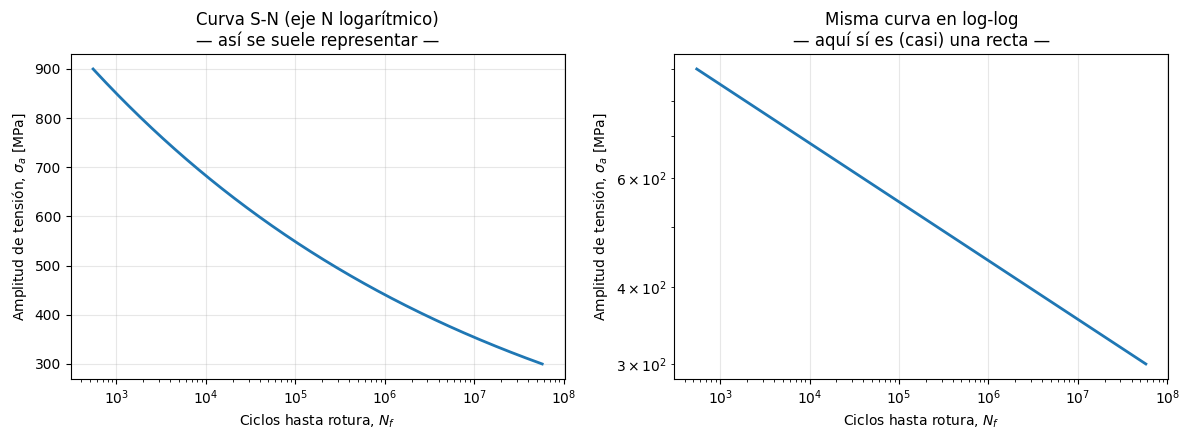

A sigma_a = 500 MPa -> N_f = 266,687 ciclos

+ 5% tension (525 MPa) -> N_f =      159,572 ciclos (x0.5983 respecto al original)
+10% tension (550 MPa) -> N_f =       97,789 ciclos (x0.3667 respecto al original)
+20% tension (600 MPa) -> N_f =       39,130 ciclos (x0.1467 respecto al original)
+30% tension (650 MPa) -> N_f =       16,850 ciclos (x0.0632 respecto al original)


In [6]:
def N_from_sigma_basquin(sigma_a, sigma_f=sigma_f_prime, b_exp=b):
    '''Ciclos hasta rotura (Basquin), zona HCF.'''
    return 0.5 * (sigma_a / sigma_f) ** (1 / b_exp)

sigma_range = np.linspace(300, 900, 400)  # MPa
N_range = N_from_sigma_basquin(sigma_range)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(N_range, sigma_range, lw=2)
axes[0].set_xscale("log")
axes[0].set_xlabel("Ciclos hasta rotura, $N_f$")
axes[0].set_ylabel("Amplitud de tensión, $\\sigma_a$ [MPa]")
axes[0].set_title("Curva S-N (eje N logarítmico)\n— así se suele representar —")

axes[1].plot(N_range, sigma_range, lw=2)
axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("Ciclos hasta rotura, $N_f$")
axes[1].set_ylabel("Amplitud de tensión, $\\sigma_a$ [MPa]")
axes[1].set_title("Misma curva en log-log\n— aquí sí es (casi) una recta —")

plt.tight_layout()
plt.show()

# Sensibilidad: cuánto cambia la vida al subir la tensión un %
sigma_ref = 500  # MPa
N_ref = N_from_sigma_basquin(sigma_ref)
print(f"A sigma_a = {sigma_ref} MPa -> N_f = {N_ref:,.0f} ciclos\n")
for pct in [5, 10, 20, 30]:
    sigma_new = sigma_ref * (1 + pct / 100)
    N_new = N_from_sigma_basquin(sigma_new)
    print(f"+{pct:>2d}% tension ({sigma_new:.0f} MPa) -> N_f = {N_new:>12,.0f} "
          f"ciclos (x{N_new/N_ref:.4f} respecto al original)")

## 1. No linealidades

### 1.1 No linealidad en una entalla: regla de Neuber + Ramberg-Osgood

En un concentrador de tensiones (entalla, agujero, radio de acuerdo, etc.) la tensión **nominal** $S$ se amplifica localmente por el factor de concentración de tensiones elástico $K_t$. Mientras el material se mantiene elástico, la tensión y la deformación locales escalan linealmente con $S$.

Pero en cuanto la tensión local supera el límite elástico, aparece plasticidad local aunque el resto de la pieza siga siendo nominalmente elástico. La **regla de Neuber** relaciona la tensión y deformación locales con las nominales elásticas:

$$K_f^2 \cdot S \cdot e = \sigma \cdot \varepsilon$$

donde $S \cdot e$ es el producto tensión·deformación nominal (elástico, $e = S/E$) y $K_f$ es el factor de concentración de tensiones a fatiga. La tensión y deformación locales reales se obtienen combinando esta ecuación con la curva cíclica tensión-deformación del material, la ecuación de **Ramberg-Osgood**:

$$\varepsilon = \frac{\sigma}{E} + \left(\frac{\sigma}{K'}\right)^{1/n'}$$

Resolviendo ambas ecuaciones a la vez para cada nivel de tensión nominal, se ve cómo la deformación local en la entalla se dispara de forma no lineal en cuanto aparece plasticidad — este es el mecanismo físico detrás de por qué la iniciación de grieta es tan sensible a la tensión.

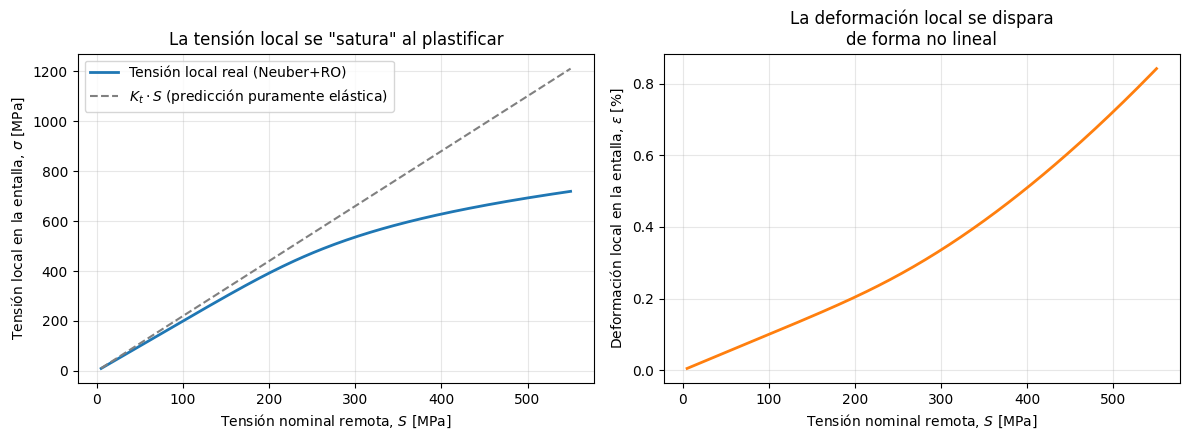

In [3]:
Kt = 2.2  # factor de concentración de tensiones elástico (entalla moderada, ejemplo)
Kf = 2.0  # factor de concentración a fatiga (algo menor que Kt por sensibilidad a la entalla)

def ramberg_osgood_strain(sigma, E=E, Kp=K_prime, np_=n_prime):
    return sigma / E + (sigma / Kp) ** (1 / np_)

def neuber_residual(sigma, S_nom, Kf_=Kf, E=E):
    '''Ecuacion de Neuber igualada a la deformacion de Ramberg-Osgood: residuo a anular.'''
    e_nom = S_nom / E
    lhs = (Kf_ ** 2) * S_nom * e_nom            # Kf^2 * S * e
    rhs = sigma * ramberg_osgood_strain(sigma)  # sigma * epsilon(sigma)
    return rhs - lhs

def local_stress_strain(S_nom):
    '''Resuelve tension y deformacion locales en la entalla para una tension nominal dada.'''
    sigma_upper = Kf * S_nom * 3 + 10  # cota superior amplia para la busqueda de raiz
    sigma_local = brentq(neuber_residual, 1e-3, sigma_upper, args=(S_nom,))
    eps_local = ramberg_osgood_strain(sigma_local)
    return sigma_local, eps_local

S_nom_range = np.linspace(5, 550, 200)  # MPa, tension nominal remota
sigma_local_arr, eps_local_arr = np.array(
    [local_stress_strain(S) for S in S_nom_range]
).T

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(S_nom_range, sigma_local_arr, lw=2, label="Tensión local real (Neuber+RO)")
axes[0].plot(S_nom_range, Kt * S_nom_range, "--", color="gray",
             label="$K_t \\cdot S$ (predicción puramente elástica)")
axes[0].set_xlabel("Tensión nominal remota, $S$ [MPa]")
axes[0].set_ylabel("Tensión local en la entalla, $\\sigma$ [MPa]")
axes[0].legend()
axes[0].set_title('La tensión local se "satura" al plastificar')

axes[1].plot(S_nom_range, eps_local_arr * 100, lw=2, color="tab:orange")
axes[1].set_xlabel("Tensión nominal remota, $S$ [MPa]")
axes[1].set_ylabel("Deformación local en la entalla, $\\varepsilon$ [%]")
axes[1].set_title("La deformación local se dispara\nde forma no lineal")

plt.tight_layout()
plt.show()

### 1.2 Ley de Paris (propagación de grieta)

Una vez existe una grieta, su velocidad de crecimiento por ciclo se relaciona con el rango del factor de intensidad de tensiones $\Delta K$ mediante la **ley de Paris**:

$$\frac{da}{dN} = C \,(\Delta K)^m \qquad \Delta K = Y \,\Delta\sigma \,\sqrt{\pi a}$$

con $a$ el tamaño de grieta, $\Delta\sigma$ el rango de tensión aplicado, $Y$ un factor geométrico (aquí $Y=1$ por simplicidad) y $m$ típicamente entre 2 y 4 para metales.

Integrando desde un tamaño de grieta inicial $a_0$ hasta un tamaño crítico $a_c$ se obtiene el número de ciclos hasta rotura $N_f$ para cada rango de tensión — y como $m > 1$, $N_f$ vuelve a depender de la tensión mediante una ley potencial, no lineal.

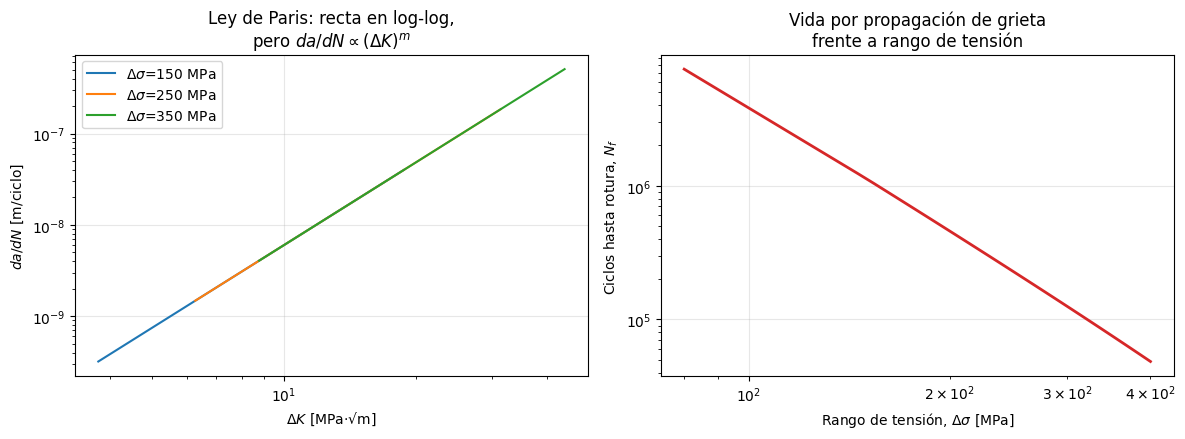

In [4]:
C = 6.0e-12   # constante de Paris (MPa, m, ciclos) - valor ilustrativo típico de acero
m = 3.0       # exponente de Paris
Y = 1.0       # factor geométrico simplificado

a0 = 0.2e-3   # m, tamaño de grieta inicial (defecto de fabricación típico, 0.2 mm)
K_IC = 60     # MPa*sqrt(m), tenacidad de fractura ilustrativa

def paris_da_dN(a, delta_sigma):
    delta_K = Y * delta_sigma * np.sqrt(np.pi * a)
    return C * delta_K ** m

def critical_crack_size(delta_sigma, sigma_max_ratio=1.6):
    # tamaño crítico a partir de K_IC con la tensión máxima del ciclo (aproximación)
    sigma_max = delta_sigma * sigma_max_ratio
    return (K_IC / (Y * sigma_max)) ** 2 / np.pi

def cycles_to_failure_paris(delta_sigma, a0=a0):
    a_c = critical_crack_size(delta_sigma)
    a_c = min(a_c, 20e-3)  # limitar a un tamano de grieta "razonable" (20 mm)
    a_vals = np.linspace(a0, a_c, 2000)
    da_dN_vals = paris_da_dN(a_vals, delta_sigma)
    dN_da = 1.0 / da_dN_vals
    N_f = np.sum((dN_da[1:] + dN_da[:-1]) / 2 * np.diff(a_vals))
    return N_f

delta_sigma_range = np.linspace(80, 400, 40)  # MPa
Nf_paris = np.array([cycles_to_failure_paris(ds) for ds in delta_sigma_range])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

a_demo = np.linspace(a0, 5e-3, 200)
for ds in [150, 250, 350]:
    dK_demo = Y * ds * np.sqrt(np.pi * a_demo)
    axes[0].loglog(dK_demo, paris_da_dN(a_demo, ds), label=f"$\\Delta\\sigma$={ds} MPa")
axes[0].set_xlabel("$\\Delta K$ [MPa·√m]")
axes[0].set_ylabel("$da/dN$ [m/ciclo]")
axes[0].set_title("Ley de Paris: recta en log-log,\npero $da/dN \\propto (\\Delta K)^m$")
axes[0].legend()

axes[1].loglog(delta_sigma_range, Nf_paris, lw=2, color="tab:red")
axes[1].set_xlabel("Rango de tensión, $\\Delta\\sigma$ [MPa]")
axes[1].set_ylabel("Ciclos hasta rotura, $N_f$")
axes[1].set_title("Vida por propagación de grieta\nfrente a rango de tensión")

plt.tight_layout()
plt.show()

## 2. Zonas del comportamiento a fatiga

La curva tensión-vida completa (**ecuación deformación-vida**) combina la componente elástica (Basquin) y la plástica (Coffin-Manson):

$$\frac{\Delta\varepsilon}{2} = \underbrace{\frac{\sigma_f'}{E}(2N_f)^b}_{\text{elástica}} + \underbrace{\varepsilon_f' (2N_f)^c}_{\text{plástica}}$$

### 2.1 Fatiga de bajo número de ciclos (LCF)

A tensiones altas (vidas cortas, $N_f$ pequeño) domina el término plástico: hay deformación plástica apreciable en cada ciclo. Trabajar en términos de deformación (Coffin-Manson) describe mejor el comportamiento que trabajar en términos de tensión (Basquin), porque la tensión se "satura" cerca del límite de fluencia mientras la deformación sigue creciendo.

### 2.2 Fatiga de alto número de ciclos (HCF)

A tensiones más bajas domina el término elástico — es la zona donde la ecuación de Basquin (sección 0) describe bien el comportamiento, porque apenas hay plasticidad macroscópica.

Entre ambas zonas hay una **vida de transición** $2N_t$ donde las componentes elástica y plástica son iguales.

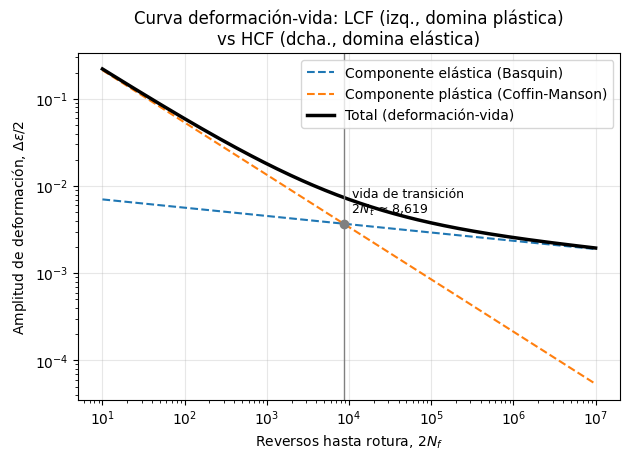

Vida de transicion LCF/HCF: 2N_t = 8,619 reversos (N_t = 4,310 ciclos)


In [5]:
N2_range = np.logspace(1, 7, 300)  # numero de reversos 2N

eps_elastic = (sigma_f_prime / E) * N2_range ** b
eps_plastic = eps_f_prime * N2_range ** c
eps_total = eps_elastic + eps_plastic

# vida de transicion: donde elastica = plastica
def transition_residual(log2N):
    N2 = 10 ** log2N
    return np.log10((sigma_f_prime / E) * N2 ** b) - np.log10(eps_f_prime * N2 ** c)

log2Nt = brentq(transition_residual, 1, 6)
N2t = 10 ** log2Nt
eps_t = eps_f_prime * N2t ** c

plt.figure()
plt.loglog(N2_range, eps_elastic, "--", label="Componente elástica (Basquin)")
plt.loglog(N2_range, eps_plastic, "--", label="Componente plástica (Coffin-Manson)")
plt.loglog(N2_range, eps_total, lw=2.5, color="k", label="Total (deformación-vida)")
plt.axvline(N2t, color="gray", lw=1)
plt.scatter([N2t], [eps_t], color="gray", zorder=5)
plt.text(N2t, eps_t * 1.3, f"  vida de transición\n  $2N_t$ ≈ {N2t:,.0f}", fontsize=9)
plt.xlabel("Reversos hasta rotura, $2N_f$")
plt.ylabel("Amplitud de deformación, $\\Delta\\varepsilon/2$")
plt.title("Curva deformación-vida: LCF (izq., domina plástica)\nvs HCF (dcha., domina elástica)")
plt.legend()
plt.show()

print(f"Vida de transicion LCF/HCF: 2N_t = {N2t:,.0f} reversos "
      f"(N_t = {N2t/2:,.0f} ciclos)")

### 2.3 Límite de fatiga (endurance limit)

En muchos aceros al carbono y aleados, la curva S-N se aplana por debajo de una cierta tensión — el **límite de fatiga** $S_e$ — normalmente en torno a $10^6$–$10^7$ ciclos. Por debajo de $S_e$, en teoría el componente no rompe por fatiga por muchos ciclos que acumule.

Una estimación clásica y muy usada en diseño preliminar (Shigley) es:

$$S_e' \approx 0.5 \, S_u \quad \text{(para aceros con } S_u \lesssim 1400 \text{ MPa)}$$

Ese valor de laboratorio $S_e'$ se corrige luego por factores reales de la pieza (acabado superficial, tamaño, tipo de carga, temperatura, fiabilidad, entalla…) para obtener el límite de fatiga aplicable a la pieza real: $S_e = S_e' \cdot k_a \cdot k_b \cdot k_c \cdots$

**Importante:** este aplanamiento NO aparece en aluminio, magnesio, titanio ni en ambientes corrosivos — ahí la curva sigue bajando (muy suavemente) indefinidamente y se habla de "resistencia a fatiga a N ciclos" en vez de límite de fatiga.

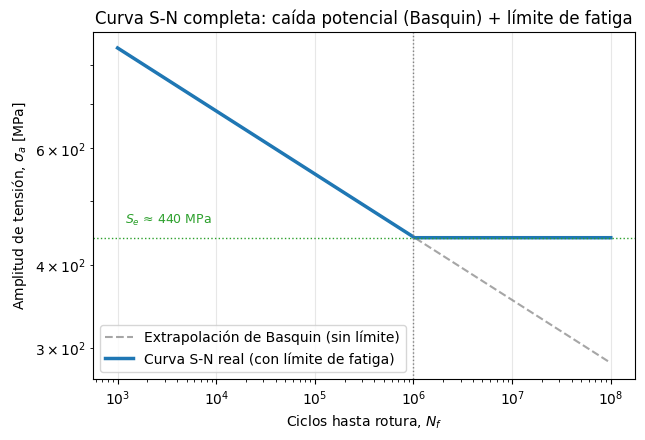

Se' (probeta pulida) = 575 MPa
Se (pieza real, factores de Marin ilustrativos ka=0.85, kb=0.9, kc=1.0) = 440 MPa


In [6]:
Se_prime = 0.5 * Su  # MPa, limite de fatiga de probeta pulida (estimacion de Shigley)

# factores de Marin simplificados e ilustrativos (acabado, tamano, carga, etc.)
ka, kb, kc = 0.85, 0.9, 1.0
Se = Se_prime * ka * kb * kc

N_knee = 1e6  # ciclos donde empieza el "codo" de la curva (tipico para aceros)

N_full = np.logspace(3, 8, 400)
sigma_basquin_full = sigma_f_prime * (2 * N_full) ** b
sigma_sn = np.where(N_full <= N_knee, sigma_basquin_full, Se)

plt.figure()
plt.loglog(N_full, sigma_basquin_full, "--", color="gray", alpha=0.7,
           label="Extrapolación de Basquin (sin límite)")
plt.loglog(N_full, sigma_sn, lw=2.5, color="tab:blue", label="Curva S-N real (con límite de fatiga)")
plt.axhline(Se, color="tab:green", lw=1, ls=":")
plt.axvline(N_knee, color="gray", lw=1, ls=":")
plt.text(1.2e3, Se * 1.05, f"$S_e$ ≈ {Se:.0f} MPa", color="tab:green", fontsize=9)
plt.xlabel("Ciclos hasta rotura, $N_f$")
plt.ylabel("Amplitud de tensión, $\\sigma_a$ [MPa]")
plt.title("Curva S-N completa: caída potencial (Basquin) + límite de fatiga")
plt.legend()
plt.show()

print(f"Se' (probeta pulida) = {Se_prime:.0f} MPa")
print(f"Se (pieza real, factores de Marin ilustrativos ka={ka}, kb={kb}, kc={kc}) = {Se:.0f} MPa")

## Para seguir explorando

- Cambia `sigma_f_prime`, `b`, `eps_f_prime`, `c`, `K_prime`, `n_prime` por los valores reales de tu material (de un ensayo de fatiga o de una base de datos como MMPDS/ASM) y repite las gráficas.
- Prueba con un $K_t$ más alto o más bajo en la sección 1.1 para ver cómo cambia la vida de iniciación.
- Añade una tensión media distinta de cero (criterios de Goodman/Gerber/Soderberg) si te interesa — puedo ampliarlo en otra iteración.
- Compara acero (con límite de fatiga) frente a aluminio (sin él) repitiendo la sección 2.3 con datos de un aluminio típico (p. ej. 2024-T3 o 7075-T6).